 $$\huge \text{ Encadenamiento (Chaining):} $$

In [ ]:
class IndiceGenomicoChaining:
  def __init__(self, capacidad):
    self.capacidad = capacidad

    # FOR COMPACTO (Comprensión de listas):
    # Crea tantas listas vacías (casillas) como indique capacidad para manejar colisiones.
    self.tabla = [[] for _ in range(capacidad)]

  def _hash(self, kmer):
    # Calcula el índice en la tabla usando la función hash propia de Python y el módulo
    return hash(kmer) % self.capacidad

  def registrar_kmer(self, kmer, posicion):
    # Encuentra la casilla correspondiente según el hash
    indice = self._hash(kmer)
    casilla = self.tabla[indice]

    # Recorre los elementos guardados en la casilla para ver si el kmer ya existe
    for i in range(len(casilla)):
      kmer_guardado = casilla[i]
      if kmer_guardado == kmer:
        # Si ya existe, añade la nueva posición a la lista de posiciones guardada
        posicion_guardado = casilla[i]
        posicion_guardado.append(posicion)
        return

    # Si el kmer no estaba en la casilla, lo agrega como una tupla (kmer, [posiciones])
    casilla.append((kmer, [posicion]))

  def buscar_posiciones(self, kmer):
    # Encuentra la casilla donde debería estar el kmer
    indice = self._hash(kmer)
    casilla = self.tabla[indice]

    # Recorre la casilla buscando la coincidencia
    for i in range(len(casilla)):
        kmer_guardado = casilla[i]
        if kmer_guardado == kmer:
            # Si lo encuentra, retorna la lista de posiciones
            return casilla[i]

    # Si recorre toda la casilla y no lo encuentra, retorna una lista vacía
    return []

In [ ]:
#Creamos nuestro índice con una capacidad pequeña para forzar colisiones
mi_indice = IndiceGenomicoChaining(capacidad=5)

#Simulamos leer el genoma "ATGCATGCTAC" por fragmentos de 4 letras
print("Registrando k-mers...")
mi_indice.registrar_kmer("ATGC", 0)
mi_indice.registrar_kmer("TGCA", 1)
mi_indice.registrar_kmer("GCAT", 2)
mi_indice.registrar_kmer("CATG", 3)
mi_indice.registrar_kmer("ATGC", 4)
mi_indice.registrar_kmer("TGCT", 5)
mi_indice.registrar_kmer("GCTA", 6)
mi_indice.registrar_kmer("CTAC", 7)

print("Registro completado!\n")

#Ponemos a prueba el método de búsqueda
print("PRUEBAS DE BÚSQUEDA")

# Prueba A: Un k-mer que aparece varias veces
print("Buscando 'ATGC':", mi_indice.buscar_posiciones("ATGC"))

# Prueba B: Un k-mer que aparece solo una vez
print("Buscando 'TGCT':", mi_indice.buscar_posiciones("TGCT"))

# Prueba C: Un k-mer que NO existe en el genoma
print("Buscando 'AAAA':", mi_indice.buscar_posiciones("AAAA"))

# Cómo quedó la memoria por dentro
print("\n--- ASÍ SE VE TU MEMORIA INTERNA ---")
for i in range(len(mi_indice.tabla)):
    print(f"Casilla {i}: {mi_indice.tabla[i]}")

Registrando k-mers...
Registro completado!

PRUEBAS DE BÚSQUEDA
Buscando 'ATGC': []
Buscando 'TGCT': []
Buscando 'AAAA': []

--- ASÍ SE VE TU MEMORIA INTERNA ---
Casilla 0: [('GCTA', [6])]
Casilla 1: [('ATGC', [0]), ('CATG', [3]), ('ATGC', [4])]
Casilla 2: [('TGCA', [1]), ('TGCT', [5])]
Casilla 3: [('GCAT', [2]), ('CTAC', [7])]
Casilla 4: []


 $$\huge \text{ Direccionamiento Abierto (Open Addressing):} $$

In [ ]:
class IndiceGenomicoOpenAddressing:
  def __init__(self, capacidad):
    self.capacidad = capacidad
    # En Hashing Cerrado, los elementos se guardan DIRECTAMENTE en la tabla
    # Inicializamos cada casilla con None para indicar que está vacía
    self.tabla = [None] * capacidad

  def _hash(self, kmer):
    return hash(kmer) % self.capacidad

  def registrar_kmer(self, kmer, posicion):
    inicio = self._hash(kmer)

    # Si hay colisión, avanzamos a la siguiente casilla
    for i in range(self.capacidad):
      indice = (inicio + i) % self.capacidad
      casilla = self.tabla[indice]

      #Casilla vacía -> Guardamos la tupla (kmer, [posiciones]) directamente aquí
      if casilla is None:
        self.tabla[indice] = (kmer, [posicion])
        return

      # La casilla ya contiene este mismo k-mer -> Agregamos la posición a su lista
      kmer_guardado, posiciones = casilla
      if kmer_guardado == kmer:
        posiciones.append(posicion)
        return

    # Si recorre toda la tabla y no encuentra casillas libres ni coincidencia
    raise OverflowError("La tabla hash está llena (alcanzó el factor de carga máximo 1.0).")

  def buscar_posiciones(self, kmer):
    inicio = self._hash(kmer)

    # PRUEBA LINEAL: Buscamos secuencialmente desde el índice inicial
    for i in range(self.capacidad):
      indice = (inicio + i) % self.capacidad
      casilla = self.tabla[indice]

      # Si encontramos un None, significa que el k-mer NUNCA fue insertado
      if casilla is None:
        return []

      kmer_guardado, posiciones = casilla
      if kmer_guardado == kmer:
        return posiciones

    return []

In [ ]:
#OTA CLAVE: Cambiamos capacidad a 10 porque tenemos 7 k-mers únicos.
# En Close Hashing cada casilla almacena solo UN k-mer, por lo que capacidad >= 7,
mi_indice = IndiceGenomicoOpenAddressing(capacidad=10)

# Simulamos leer el genoma "ATGCATGCTAC" por fragmentos de 4 letras
print("Registrando k-mers...")
mi_indice.registrar_kmer("ATGC", 0)
mi_indice.registrar_kmer("TGCA", 1)
mi_indice.registrar_kmer("GCAT", 2)
mi_indice.registrar_kmer("CATG", 3)
mi_indice.registrar_kmer("ATGC", 4)  # k-mer repetido: añade la posición 4 a 'ATGC'
mi_indice.registrar_kmer("TGCT", 5)
mi_indice.registrar_kmer("GCTA", 6)
mi_indice.registrar_kmer("CTAC", 7)

print("Registro completado!\n")

# Pruebas de búsqueda
print("PRUEBAS DE BÚSQUEDA")

# Prueba A: Un k-mer que aparece varias veces
print("Buscando 'ATGC':", mi_indice.buscar_posiciones("ATGC"))

# Prueba B: Un k-mer que aparece solo una vez
print("Buscando 'TGCT':", mi_indice.buscar_posiciones("TGCT"))

# Prueba C: Un k-mer que NO existe en el genoma
print("Buscando 'AAAA':", mi_indice.buscar_posiciones("AAAA"))

# Estado de la memoria interna
print("\n--- ASÍ SE VE TU MEMORIA INTERNA ---")
for i in range(len(mi_indice.tabla)):
    print(f"Casilla {i}: {mi_indice.tabla[i]}")


Registrando k-mers...
Registro completado!

PRUEBAS DE BÚSQUEDA
Buscando 'ATGC': [0, 4]
Buscando 'TGCT': [5]
Buscando 'AAAA': []

--- ASÍ SE VE TU MEMORIA INTERNA ---
Casilla 0: None
Casilla 1: ('ATGC', [0, 4])
Casilla 2: ('TGCA', [1])
Casilla 3: ('TGCT', [5])
Casilla 4: ('CTAC', [7])
Casilla 5: ('GCTA', [6])
Casilla 6: ('CATG', [3])
Casilla 7: None
Casilla 8: ('GCAT', [2])
Casilla 9: None


# Paradoja del Cumpleaños

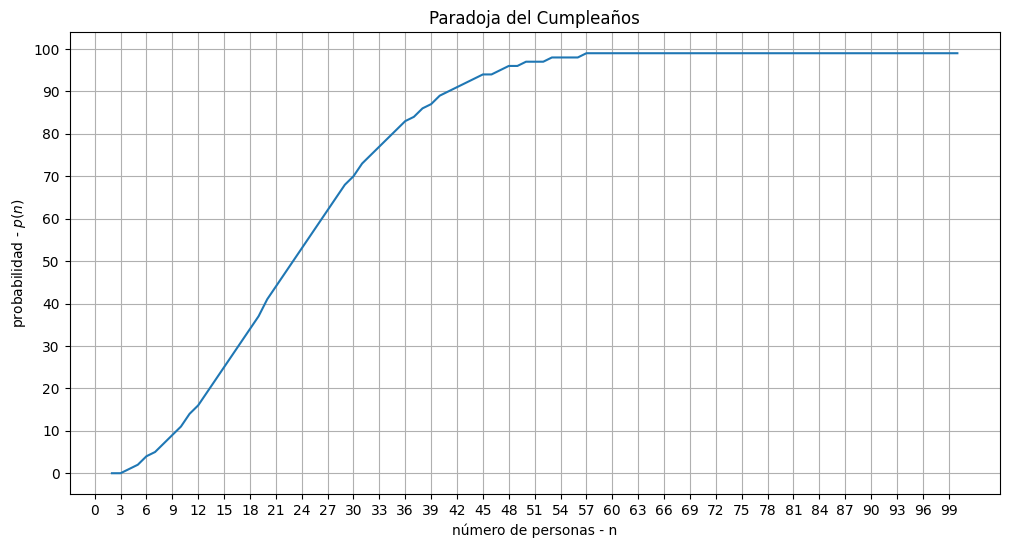

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def prob_cump (n):
  prob = 1                  #probabilidad de que n personas no cumplan años el mismo dia
  for i in range(n):
    prob = prob*(1-i/365)
  return (1-prob)*100       #probabilidad de que n personas cumplan años el mismo dia

num_per = np.arange(2,101,1)
prob = np.zeros_like(num_per)
for i in range(len(num_per)):
  prob[i] = prob_cump(num_per[i])

#Gráficamos número de personas - n vs probabilidad - p(n)
plt.figure(figsize=(12,6))
plt.plot(num_per,prob)
plt.title(f'Paradoja del Cumpleaños')
plt.xlabel(f'número de personas - n')
plt.ylabel(f'probabilidad - $p(n)$')
plt.grid()

#Añadimos más puntos en la gráfica
plt.xticks(np.arange(0, 101, 3))
plt.yticks(np.arange(0, 101, 10))

plt.show()

In [ ]:
print(f'La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 23 personas es p(23)={prob_cump(23)}')

La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 23 personas es p(23)=50.72972343239854


In [ ]:
print(f'La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 41 personas es p(41)={prob_cump(41)}')

La probabilidad de que al menos dos personas cumplan años el mismo dia en un grupo de 41 personas es p(41)=90.31516114817354


# Generar Secuencias de ADN Aleatorias

In [ ]:
import random as rand

def generar_dna(longitud):
    sec_dna = list()
    bases = ['A','C','G','T']
    for i in range(longitud):
        sec_dna.append(rand.choice(bases))     # Selecciona aleatoriamente una base
    return ''.join(sec_dna)

In [ ]:
print(f'La secuencia de ADN generada es: {generar_dna(50)}')

La secuencia de ADN generada es: GCAGTTAAGTTACCGTAGCGACACGCCAAAGTCCAGGGCCGGCGGTATGC


# Generar Secuencias de ADN Mutadas

In [ ]:
import random as rand

def mutar_dna(secuencia, tasa_mutacion):      #0 <= tasa_mutacion <= 1
    bases = ['A', 'C', 'G', 'T']
    secuencia_mutada = list(secuencia)
    for i in range(len(secuencia_mutada)):
        if rand.random() < tasa_mutacion:     #Condición de para mutar una base de la secuencia
            #Seleccionamos las bases distintas para hacer la mutación
            opciones = [b for b in bases if b != secuencia_mutada[i]]
            secuencia_mutada[i] = rand.choice(opciones)
    return ''.join(secuencia_mutada)

In [ ]:
g = generar_dna(50)
print(f'La secuencia de ADN generada es: {g}')
g_mutada = mutar_dna(g,0.1)
print(f'La secuencia de ADN mutada a un {0.1*100}% es: {g_mutada}')

La secuencia de ADN generada es: TGGGGTGGCTGACGTCGCGTCATACACTAGCAATTGATCAAGGTCAATTT
La secuencia de ADN mutada a un 10.0% es: TGGCATGGCCGTCGACGCGTCATACACTAGCAATTGATCAAAGTAAATTT


# Construcción del Conjunto de los k-meros

In [ ]:
def k_meros(secuencia,k): # 1 <= k <= len(secuencia)
  kmeros= set()
  if k > len(secuencia):
    return None
  elif k == len(secuencia):
    kmeros.add(secuencia)
    return kmeros
  else:
    for i in range(len(secuencia)-(k-1)):
      kmeros.add(secuencia[i:i+k])
    return kmeros

In [ ]:
g = generar_dna(30)
print(f'La secuencia de ADN generada es g={g}')
#construimos el conjunto de los k-meros de g
k=15
kmeros = k_meros(g,k)
print(f'El conjunto de {k}-meros de g es:')
for k in kmeros:
  print(k)

La secuencia de ADN generada es g=GGTCACACGACATCCTATGATACGCCTCAA
El conjunto de 15-meros de g es:
CACGACATCCTATGA
CGACATCCTATGATA
ACATCCTATGATACG
TCCTATGATACGCCT
CCTATGATACGCCTC
ATCCTATGATACGCC
ACGACATCCTATGAT
GTCACACGACATCCT
CACACGACATCCTAT
TCACACGACATCCTA
ACACGACATCCTATG
TATGATACGCCTCAA
CATCCTATGATACGC
CTATGATACGCCTCA
GACATCCTATGATAC
GGTCACACGACATCC
